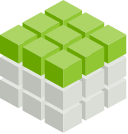

# Kumo Tabular on Breast Mass Classification (Kaggle)

**Kumo Tabular** is a structured-data foundation model for predictive AI on a single table. It uses labelled context rows to predict outcomes for new rows without training a task-specific model.

This notebook runs a **binary classification** task with the Mammographic Mass dataset from **Kaggle**, using `structured-data-models-client` to call a deployed **Kumo Tabular NVIDIA NIM**. It demonstrates both a direct `Request` and a Predictive Query Language (PQL) workflow.

**A GPU is not required on the notebook machine.** The model runs on the NIM server. This notebook reads the dataset from an existing Snowflake stage using an active Snowpark session.

The client identifies the model as `KumoTabular()`; its size is determined by the server's deployed checkpoint. Local PyTorch `size`, `device`, and ensemble settings do not configure the NIM.

See the [Kumo Tabular overview](https://docs.nvidia.com/sdgm/kumo-tabular/about-kumo-tabular/overview), [quickstart](https://docs.nvidia.com/sdgm/kumo-tabular/get-started/quickstart), and [client repository](https://github.com/NVIDIA/structured-data-models-client).

Each user is responsible for checking the content of datasets and the applicable licenses and determining if suitable for the intended use.

## 1. Install and connect

Use a Python 3.10 or newer kernel with network access to the NIM endpoint and an active Snowflake session for the dataset. The notebook also uses pandas, NumPy, and scikit-learn.

Install the base client; the relational extra is not needed. See [Install and Connect](https://docs.nvidia.com/sdgm/kumo-tabular/get-started/sdk-getting-started).

In [ ]:
%pip install structured-data-models-client scikit-learn

In [ ]:
import os

from sdm_client import KumoTabular, PredictiveQuery, Request, Schema, SDMClient

# Override the endpoint through environment configuration when needed.
nim_endpoint = os.environ.get(
    'KUMO_TABULAR_API_ENDPOINT',
    'http://<dns_name>:8000',
)

nim_api_key = os.environ.get('KUMO_TABULAR_API_KEY')

In [ ]:
# Check the models served by the configured NIM endpoint.
with SDMClient(url=nim_endpoint, api_key=nim_api_key) as client:
    print(client.models())

## 2. Load the dataset

**Dataset:** [Mammographic Mass Data Set (Kaggle)](https://www.kaggle.com/datasets/overratedgman/mammographic-mass-data-set), version 3

**Task:** Binary classification of breast masses: benign (0) or malignant (1)

Use four predictors: `Age`, `Shape`, `Margin`, and `Density`.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from snowflake.snowpark.context import get_active_session

# Read the Kaggle CSV uploaded to the stage
session = get_active_session()
with session.file.get_stream(
    '@<database>.<schema>.<stage>/Cleaned_data.csv'
) as f:
    data = pd.read_csv(f)

# Select predictors and readable class labels
X = data[['Age', 'Shape', 'Margin', 'Density']]
y = data['Severity'].map({0: 'benign', 1: 'malignant'})
classes = sorted(y.unique())
df = X.assign(target=pd.Categorical(y, categories=classes))

# Split ICL examples ("train") and test sets
train, test = train_test_split(
    data.index,
    test_size=0.2,
    stratify=y,
    random_state=0,
)

## 3. Prepare rows and run Kumo Tabular through the NIM

Use the training split as labelled `context` and the held-out test split as `predict`. The target column must be present only in the context. A row ID lets PQL identify entities and keeps the held-out rows distinct from the context.

The explicit schema preserves the original numerical and categorical feature types. The NIM accepts `task="classification"` for both binary and multiclass tasks. Direct requests support up to 10,000 context rows; this dataset fits within that limit.

See [Make Predictions](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions).

In [ ]:
context = df.iloc[train].copy()
to_score = df.iloc[test].drop(columns='target').copy()
context.insert(0, 'row_id', train)
to_score.insert(0, 'row_id', test)

schema = Schema.from_data(
    {'masses': context},
    primary_keys={'masses': 'row_id'},
    relationships=[],
)
for column, stype in {
    'Age': 'numerical',
    'Density': 'numerical',
    'Shape': 'categorical',
    'Margin': 'categorical',
    'target': 'categorical',
}.items():
    schema['masses'][column].stype = stype
schema.check_consistent()

request = Request(
    context=context,
    predict=to_score,
    target='target',
    task='classification',
    schema=schema,
    entity_table='masses',
)

with SDMClient(url=nim_endpoint, api_key=nim_api_key) as client:
    result = client.predict(
        request,
        model=KumoTabular(),
        outputs=['prediction', 'probabilities'],
    )

## 4. Read the predictions

`PredictionResult.to_pandas()` returns `row_index`, `prediction`, and `probability_<class>` columns. `row_index` refers to the zero-based position within `to_score`, not its pandas index. Align on it before evaluating against the test labels.

See [Understand Prediction Results](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/work-with-prediction-results/prediction-results).

In [ ]:
answers = (
    result.to_pandas().set_index('row_index').reindex(range(len(to_score)))
)
predictions = answers['prediction'].to_numpy()
probabilities = answers[
    [f'probability_{label}' for label in classes]
].to_numpy()
answers.head()

## 5. Evaluate predictions

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

baseline = DummyClassifier(strategy='most_frequent').fit(
    X.iloc[train], y.iloc[train]
)
pd.DataFrame(
    {
        'Model': ['Kumo Tabular (NIM)', 'Majority class'],
        'Accuracy': [
            accuracy_score(y.iloc[test], predictions),
            accuracy_score(y.iloc[test], baseline.predict(X.iloc[test])),
        ],
        'ROC AUC': [
            roc_auc_score(
                y.iloc[test], probabilities[:, classes.index('malignant')]
            ),
            roc_auc_score(
                y.iloc[test],
                baseline.predict_proba(X.iloc[test])[
                    :, list(baseline.classes_).index('malignant')
                ],
            ),
        ],
    }
).set_index('Model').round(4)

## 6. Run the same task with a predictive query (PQL)

PQL names the prediction target and entity. Here `PREDICT masses.target FOR EACH masses.row_id` asks for each mass's benign/malignant label. `materialize()` builds the request, and `client.predict()` sends it to the NIM.

Reuse the schema built from **training rows only** and supply the held-out feature rows with `predict=to_score`. This keeps test labels out of the prediction context. Pass `task="classification"` explicitly. Both workflows use the same context, test split, and semantic types; predictions can vary between calls.

For rows already in a schema's table, `materialize(indices=[...], task="classification")` selects rows by primary-key value and excludes them from context. The `predict=` form below scores rows supplied separately.

See [Make Predictions with PQL](https://docs.nvidia.com/sdgm/kumo-tabular/user-guide/make-predictions/make-predictions#ask-in-pql).

In [ ]:
query = PredictiveQuery(
    'PREDICT masses.target FOR EACH masses.row_id',
    schema,
)
pql_request = query.materialize(
    predict=to_score,
    task='classification',
    model=KumoTabular(),
)

with SDMClient(url=nim_endpoint, api_key=nim_api_key) as client:
    pql_result = client.predict(
        pql_request,
        model=KumoTabular(),
        outputs=['prediction', 'probabilities'],
    )

pql_answers = (
    pql_result.to_pandas().set_index('row_index').reindex(range(len(to_score)))
)
pql_answers.head()

In [ ]:
pd.DataFrame(
    {
        'Model': ['Kumo Tabular (NIM, PQL)'],
        'Accuracy': [accuracy_score(y.iloc[test], pql_answers['prediction'])],
        'ROC AUC': [
            roc_auc_score(y.iloc[test], pql_answers['probability_malignant'])
        ],
    }
).set_index('Model').round(4)

## Next Steps

### Check out other available Structured Data Foundation Models:
- [Kumo-Relational](https://huggingface.co/nvidia/Kumo-Relational)
- [Kumo-Anomaly](https://huggingface.co/nvidia/Kumo-Anomaly)
- [Kumo-Forecast](https://huggingface.co/nvidia/Kumo-Forecast)

### Check out Kumo Engine
To run foundation models for structured data in production at scale, check out Kumo Engine
- [Documentation](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/overview)